# CNN Representation Tutorial

A compact, tutorial-style PyTorch lesson notebook for:
1. Manually applying a convolution filter on a tiny toy image
2. Training a simple CNN on Fashion-MNIST
3. Inspecting representations learned at different layers

This notebook saves figures into `outputs_cnn_tutorial/`.

Designed for teaching: the code includes explanatory comments throughout.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

try:
    import umap
except ImportError:
    umap = None

SEED = 42
EPOCHS = 3
BATCH_SIZE = 128
LR = 1e-3

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
output_dir = Path("outputs_cnn_tutorial")
output_dir.mkdir(exist_ok=True, parents=True)

print(f"Using device: {device}")
print(f"Figures will be saved to: {output_dir.resolve()}")

Using device: cpu
Figures will be saved to: /home/michelangelo/Desktop/DL/Sign-Language-CNN/outputs_cnn_tutorial


## Manual Convolution on a Tiny Image

The goal is pedagogical:
- images are grids of numbers
- a filter is a small grid of weights
- the convolution output is produced by sliding the filter over the image
- each output value is a weighted sum over a local patch


MANUAL FILTER DEMO
Toy image:
 tensor([[0., 0., 0., 0., 0.],
        [0., 1., 1., 1., 0.],
        [0., 1., 2., 1., 0.],
        [0., 1., 1., 1., 0.],
        [0., 0., 0., 0., 0.]])

Filter / kernel:
 tensor([[-1.,  0.,  1.],
        [-1.,  0.,  1.],
        [-1.,  0.,  1.]])

Patch at position (0, 0):
tensor([[0., 0., 0.],
        [0., 1., 1.],
        [0., 1., 2.]])
Element-wise product patch * kernel:
tensor([[-0., 0., 0.],
        [-0., 0., 1.],
        [-0., 0., 2.]])
Sum = 3.0

Patch at position (0, 1):
tensor([[0., 0., 0.],
        [1., 1., 1.],
        [1., 2., 1.]])
Element-wise product patch * kernel:
tensor([[-0.,  0.,  0.],
        [-1.,  0.,  1.],
        [-1.,  0.,  1.]])
Sum = 0.0

Patch at position (0, 2):
tensor([[0., 0., 0.],
        [1., 1., 0.],
        [2., 1., 0.]])
Element-wise product patch * kernel:
tensor([[-0.,  0.,  0.],
        [-1.,  0.,  0.],
        [-2.,  0.,  0.]])
Sum = -3.0

Patch at position (1, 0):
tensor([[0., 1., 1.],
        [0., 1., 2.],
     

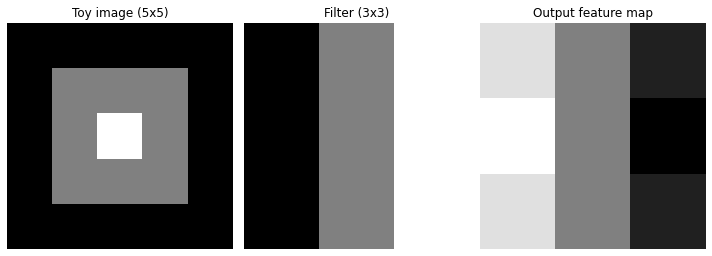

In [2]:
# A small "image" with a bright square-ish pattern in the center
image = torch.tensor([
    [0., 0., 0., 0., 0.],
    [0., 1., 1., 1., 0.],
    [0., 1., 2., 1., 0.],
    [0., 1., 1., 1., 0.],
    [0., 0., 0., 0., 0.],
])

# A simple edge-like filter (vertical emphasis)
kernel = torch.tensor([
    [-1., 0., 1.],
    [-1., 0., 1.],
    [-1., 0., 1.],
])

# No padding, stride 1
out_h = image.shape[0] - kernel.shape[0] + 1
out_w = image.shape[1] - kernel.shape[1] + 1
output = torch.zeros((out_h, out_w))

print("\n" + "=" * 80)
print("MANUAL FILTER DEMO")
print("=" * 80)
print("Toy image:\n", image)
print("\nFilter / kernel:\n", kernel)

for i in range(out_h):
    for j in range(out_w):
        patch = image[i:i+3, j:j+3]
        value = (patch * kernel).sum()
        output[i, j] = value

        print(f"\nPatch at position ({i}, {j}):")
        print(patch)
        print("Element-wise product patch * kernel:")
        print(patch * kernel)
        print(f"Sum = {value.item():.1f}")

print("\nFinal output feature map:\n", output)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))

axes[0].imshow(image.numpy(), cmap="gray")
axes[0].set_title("Toy image (5x5)")
axes[0].axis("off")

axes[1].imshow(kernel.numpy(), cmap="gray")
axes[1].set_title("Filter (3x3)")
axes[1].axis("off")

axes[2].imshow(output.numpy(), cmap="gray")
axes[2].set_title("Output feature map")
axes[2].axis("off")

plt.tight_layout()
fig.savefig(output_dir / "01_manual_filter_demo.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## Data

Fashion-MNIST is a good teaching dataset:
- same size as MNIST (`28x28` grayscale)
- simple enough to train quickly
- slightly less trivial than handwritten digits

100%|██████████| 26.4M/26.4M [00:06<00:00, 4.16MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 825kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.15MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 6.59MB/s]


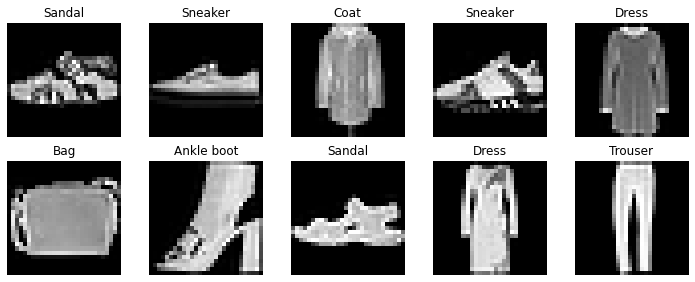

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [3]:
def get_dataloaders(batch_size: int):
    transform = transforms.ToTensor()

    train_dataset = datasets.FashionMNIST(
        root="./data",
        train=True,
        download=True,
        transform=transform,
    )
    test_dataset = datasets.FashionMNIST(
        root="./data",
        train=False,
        download=True,
        transform=transform,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
    )

    class_names = train_dataset.classes
    return train_loader, test_loader, class_names


train_loader, test_loader, class_names = get_dataloaders(BATCH_SIZE)
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
axes = axes.flatten()

for i in range(10):
    axes[i].imshow(images[i, 0].numpy(), cmap="gray")
    axes[i].set_title(class_names[labels[i].item()])
    axes[i].axis("off")

plt.tight_layout()
fig.savefig(output_dir / "02_dataset_samples.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

class_names

## The Model

We use a small CNN with a clear separation between feature extraction and classification.

Pedagogically, this is useful because the hidden activations become concrete learned representations:
- early layers detect local patterns
- deeper layers build more abstract features
- the classifier turns those features into class logits

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes: int = 10):
        super().__init__()

        # First block:
        # input  : (B, 1, 28, 28)
        # conv1  : (B, 16, 28, 28)
        # pool1  : (B, 16, 14, 14)
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2)

        # Second block:
        # input  : (B, 16, 14, 14)
        # conv2  : (B, 32, 14, 14)
        # pool2  : (B, 32, 7, 7)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2)

        # Classifier head:
        # flatten: 32 * 7 * 7 = 1568
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x, return_activations: bool = False):
        activations = {}

        x = self.conv1(x)
        activations["conv1"] = x

        x = self.relu1(x)
        activations["relu1"] = x

        x = self.pool1(x)
        activations["pool1"] = x

        x = self.conv2(x)
        activations["conv2"] = x

        x = self.relu2(x)
        activations["relu2"] = x

        x = self.pool2(x)
        activations["pool2"] = x

        x = torch.flatten(x, 1)
        activations["flatten"] = x

        x = self.fc1(x)
        activations["fc1"] = x

        x = self.relu3(x)
        activations["relu3"] = x

        logits = self.fc2(x)
        activations["logits"] = logits

        if return_activations:
            return logits, activations
        return logits

In [7]:
model = SimpleCNN(num_classes=10).to(device)

x = torch.randn(1, 1, 28, 28).to(device)
_, activations = model(x, return_activations=True)

print("\n" + "=" * 80)
print("SHAPE TRACE THROUGH THE NETWORK")
print("=" * 80)
print(f"input   : {tuple(x.shape)}")
for name, tensor in activations.items():
    print(f"{name:8s}: {tuple(tensor.shape)}")


SHAPE TRACE THROUGH THE NETWORK
input   : (1, 1, 28, 28)
conv1   : (1, 16, 28, 28)
relu1   : (1, 16, 28, 28)
pool1   : (1, 16, 14, 14)
conv2   : (1, 32, 14, 14)
relu2   : (1, 32, 14, 14)
pool2   : (1, 32, 7, 7)
flatten : (1, 1568)
fc1     : (1, 128)
relu3   : (1, 128)
logits  : (1, 10)


[W702 11:19:13.825213345 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W702 11:19:13.828668714 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


## Training and Evaluation

This section contains a minimal but complete PyTorch training loop.

Notes for students:
- `model.train()` enables training behavior
- `model.eval()` switches to inference mode
- `torch.no_grad()` disables gradient computation during evaluation
- `CrossEntropyLoss` expects raw logits, not softmax probabilities

In [5]:
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * images.size(0)
            preds = logits.argmax(dim=1)
            total_correct += (preds == labels).sum().item()
            total_samples += images.size(0)

    avg_loss = total_loss / total_samples
    accuracy = total_correct / total_samples
    return avg_loss, accuracy


def train(model, train_loader, test_loader, epochs, lr, device):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": [],
    }

    for epoch in range(1, epochs + 1):
        model.train()

        running_loss = 0.0
        running_correct = 0
        running_samples = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            preds = logits.argmax(dim=1)
            running_correct += (preds == labels).sum().item()
            running_samples += images.size(0)

        train_loss = running_loss / running_samples
        train_acc = running_correct / running_samples
        test_loss, test_acc = evaluate(model, test_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train_loss={train_loss:.4f}, train_acc={train_acc:.4f} | "
            f"test_loss={test_loss:.4f}, test_acc={test_acc:.4f}"
        )

    return history

Epoch 01/3 | train_loss=0.5739, train_acc=0.7940 | test_loss=0.4037, test_acc=0.8548
Epoch 02/3 | train_loss=0.3502, train_acc=0.8735 | test_loss=0.3553, test_acc=0.8729
Epoch 03/3 | train_loss=0.3020, train_acc=0.8906 | test_loss=0.3203, test_acc=0.8840


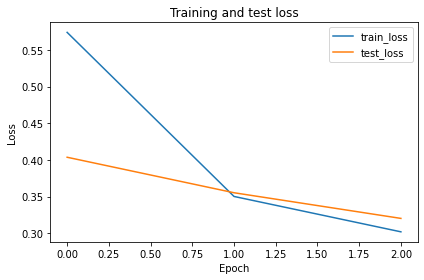

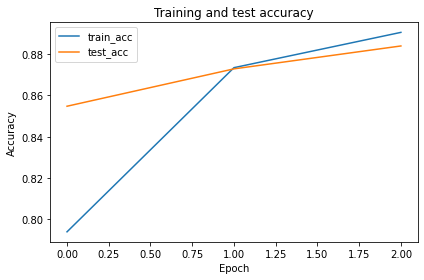

In [8]:
history = train(
    model=model,
    train_loader=train_loader,
    test_loader=test_loader,
    epochs=EPOCHS,
    lr=LR,
    device=device,
)

plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="train_loss")
plt.plot(history["test_loss"], label="test_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and test loss")
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "03_loss_curve.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()

plt.figure(figsize=(6, 4))
plt.plot(history["train_acc"], label="train_acc")
plt.plot(history["test_acc"], label="test_acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and test accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "04_accuracy_curve.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()

## Inspecting Learned Representations

Now we inspect what the network has learned at different depths.

We will:
- visualize feature maps for one test image
- summarize each layer representation as a vector
- compare how representations evolve from shallow to deep layers

[W702 11:27:29.240272594 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W702 11:27:29.242746427 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


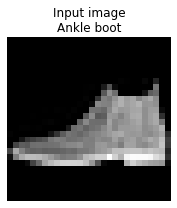

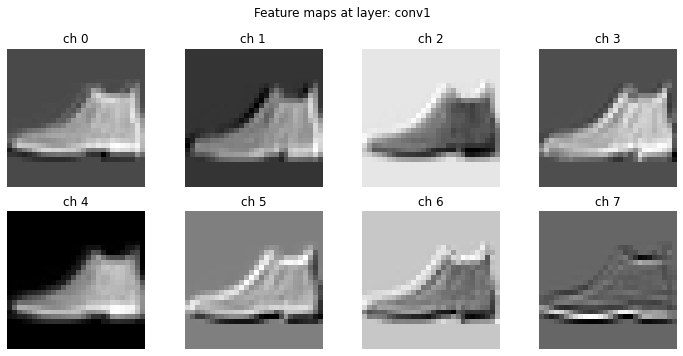

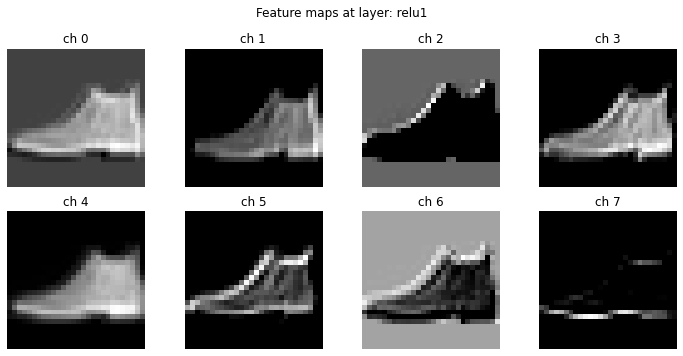

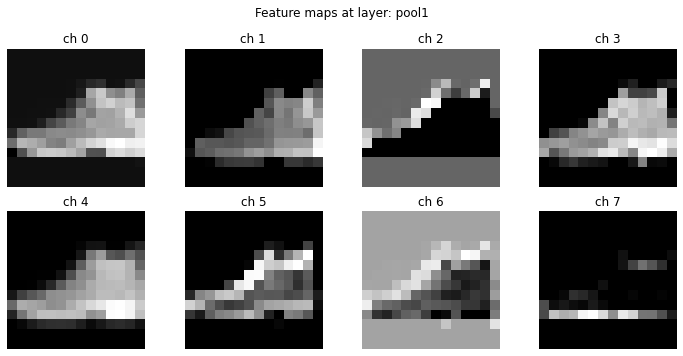

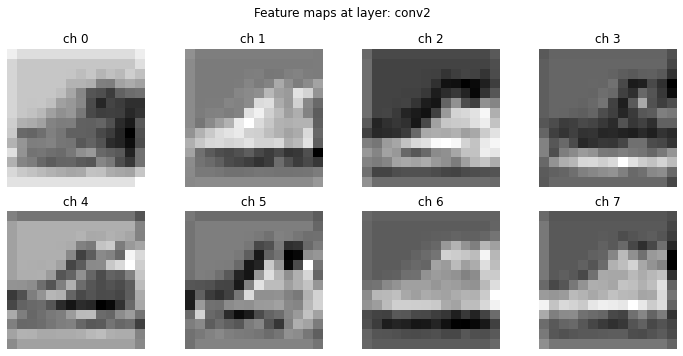

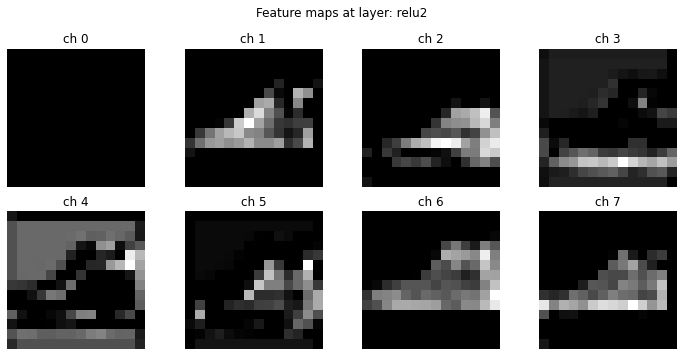

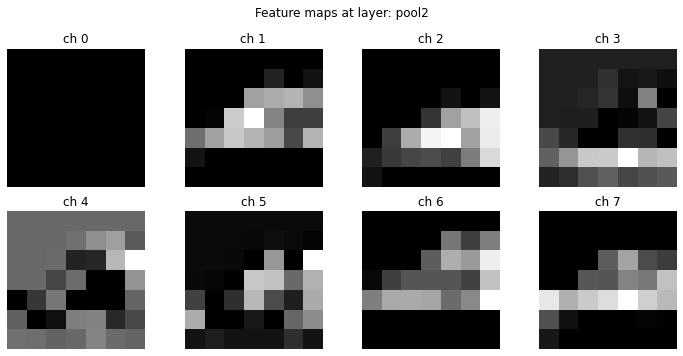

In [9]:
def show_feature_maps(model, loader, class_names, device, output_dir):
    model.eval()
    images, labels = next(iter(loader))
    image = images[0:1].to(device)
    label = labels[0].item()

    with torch.no_grad():
        _, activations = model(image, return_activations=True)

    plt.figure(figsize=(3, 3))
    plt.imshow(image[0, 0].cpu().numpy(), cmap="gray")
    plt.title(f"Input image\n{class_names[label]}")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(output_dir / "05_input_example.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

    layers_to_show = ["conv1", "relu1", "pool1", "conv2", "relu2", "pool2"]

    for layer_name in layers_to_show:
        feat = activations[layer_name][0].detach().cpu()
        n_channels = min(8, feat.shape[0])

        fig, axes = plt.subplots(2, 4, figsize=(10, 5))
        axes = axes.flatten()

        for i in range(8):
            axes[i].axis("off")

        for i in range(n_channels):
            axes[i].imshow(feat[i].numpy(), cmap="gray")
            axes[i].set_title(f"ch {i}")
            axes[i].axis("off")

        fig.suptitle(f"Feature maps at layer: {layer_name}", y=0.98)
        plt.tight_layout()
        fig.savefig(output_dir / f"06_{layer_name}_feature_maps.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close(fig)


show_feature_maps(model, test_loader, class_names, device, output_dir)

[W702 11:28:54.231100243 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W702 11:28:54.253208325 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


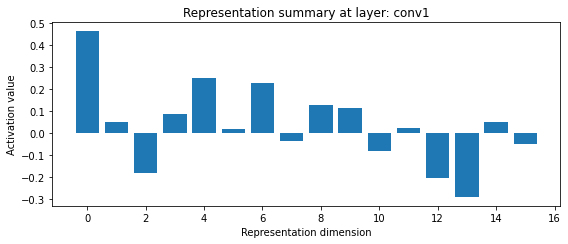

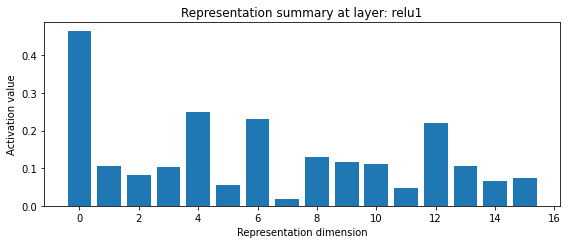

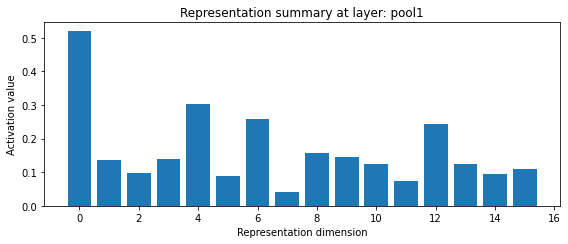

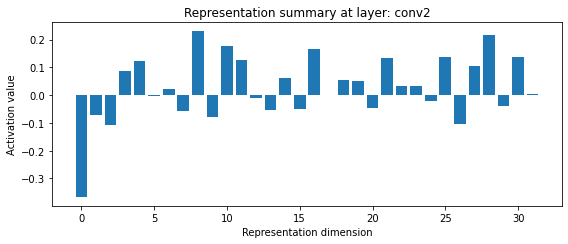

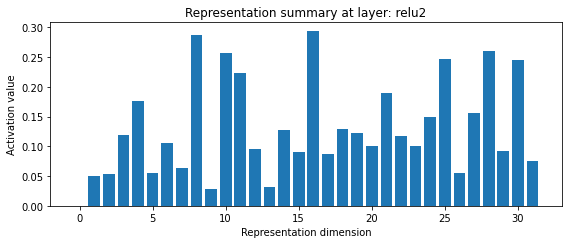

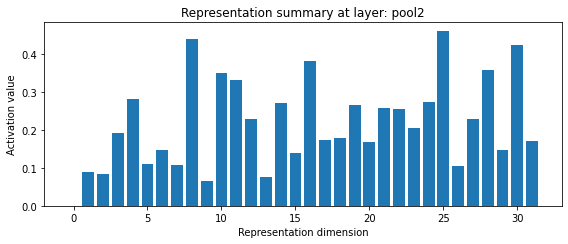

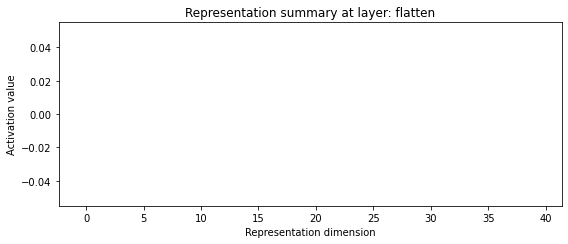

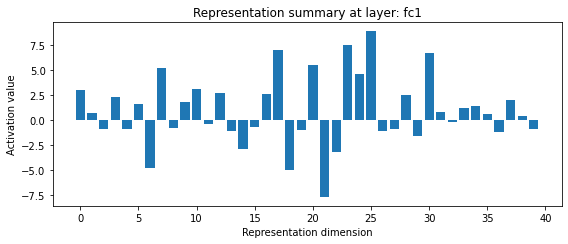

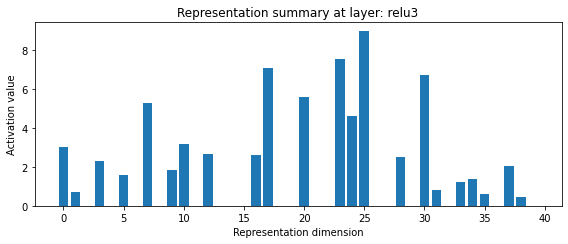

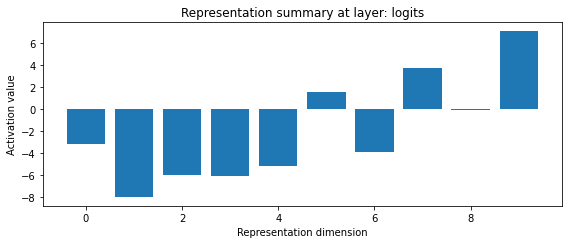


Saved representation summaries for layers:
 - conv1
 - relu1
 - pool1
 - conv2
 - relu2
 - pool2
 - flatten
 - fc1
 - relu3
 - logits


In [10]:
def show_representation_summaries(model, loader, device, output_dir):
    model.eval()
    images, labels = next(iter(loader))
    image = images[0:1].to(device)

    with torch.no_grad():
        _, activations = model(image, return_activations=True)

    summary_vectors = {}

    for name, tensor in activations.items():
        t = tensor[0].detach().cpu()

        if t.ndim == 3:
            summary_vectors[name] = t.mean(dim=(1, 2))
        elif t.ndim == 1:
            summary_vectors[name] = t

    for name, vec in summary_vectors.items():
        vec = vec.numpy()
        shown = vec[:40]

        plt.figure(figsize=(8, 3.5))
        plt.bar(range(len(shown)), shown)
        plt.xlabel("Representation dimension")
        plt.ylabel("Activation value")
        plt.title(f"Representation summary at layer: {name}")
        plt.tight_layout()
        plt.savefig(output_dir / f"07_repr_{name}.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()

    print("\nSaved representation summaries for layers:")
    for name in summary_vectors.keys():
        print(f" - {name}")


show_representation_summaries(model, test_loader, device, output_dir)

## UMAP of Internal Representations

Each point in the next plots corresponds to one test image.

Why this is useful pedagogically:
- points that end up close together have similar internal representations
- deeper layers often separate classes better than early layers
- this gives a geometric view of representation learning

If `umap-learn` is not installed, the next cell will skip this section.

In [ ]:
def collect_layer_representations(model, loader, device):
    model.eval()

    collected = {
        "conv1": [],
        "relu1": [],
        "pool1": [],
        "conv2": [],
        "relu2": [],
        "pool2": [],
        "flatten": [],
        "fc1": [],
        "relu3": [],
        "logits": [],
    }
    labels_all = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            _, activations = model(images, return_activations=True)

            for name, tensor in activations.items():
                if tensor.ndim == 4:
                    vec = tensor.mean(dim=(2, 3))
                elif tensor.ndim == 2:
                    vec = tensor
                else:
                    continue

                collected[name].append(vec.cpu())

            labels_all.append(labels)

    for name in collected:
        collected[name] = torch.cat(collected[name], dim=0).numpy()

    labels_all = torch.cat(labels_all, dim=0).numpy()
    return collected, labels_all


def show_umap_projections(model, loader, class_names, device, output_dir):
    if umap is None:
        print(
            "UMAP was requested, but the 'umap-learn' package is not installed.\n"
            "Install it with: pip install umap-learn\n"
            "Skipping UMAP plots."
        )
        return

    reps, labels = collect_layer_representations(model, loader, device)
    layers_to_plot = ["conv1", "pool1", "conv2", "pool2", "fc1", "logits"]

    for layer_name in layers_to_plot:
        X = reps[layer_name]
        reducer = umap.UMAP(
            n_components=2,
            n_neighbors=15,
            min_dist=0.5,
            metric="euclidean",
            random_state=42,
        )
        embedding = reducer.fit_transform(X)

        plt.figure(figsize=(7, 6))
        n_classes = len(class_names)
        cmap_name = "tab10" if n_classes <= 10 else "tab20"
        cmap = plt.get_cmap(cmap_name)

        for cls in range(n_classes):
            mask = labels == cls
            if mask.sum() == 0:
                continue
            color = cmap(cls % getattr(cmap, "N", n_classes))
            plt.scatter(
                embedding[mask, 0],
                embedding[mask, 1],
                s=10,
                alpha=0.7,
                color=color,
                label=class_names[cls],
                linewidths=0,
            )

        plt.xlabel("UMAP 1")
        plt.ylabel("UMAP 2")
        plt.title(f"Test-set UMAP at layer: {layer_name}")
        plt.legend(markerscale=2, fontsize="small", loc="best")
        plt.tight_layout()
        plt.savefig(output_dir / f"08_umap_{layer_name}.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()

    print("\nSaved UMAP projections for layers:")
    for layer_name in layers_to_plot:
        print(f" - {layer_name}")


show_umap_projections(model, test_loader, class_names, device, output_dir)

## Exercise

Implement a **CNN autoencoder**.

An autoencoder is a neural network trained to reconstruct its own input:
- the **encoder** compresses the image into a more compact representation
- the **bottleneck** is the most compressed latent representation
- the **decoder** expands that latent code back into an image

Why this is interesting:
- the network is forced to keep only the most useful information
- internal activations can be studied as learned representations
- we can compare a middle encoder layer against the bottleneck with UMAP

Your tasks:
1. complete the CNN autoencoder layers
2. train it to reconstruct Fashion-MNIST images
3. extract representations from the **middle layer of the encoder** and from the **bottleneck**
4. visualize those two representations with UMAP



# Deconvolution
To reconstruct the image from the bottleneck representation, we need to use **convolutional transpose layers** (also known as deconvolution layers). These layers perform the opposite operation of convolution, allowing us to upsample the feature maps back to the original image size.



In [ ]:
class CNNAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc_conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.enc_relu1 = nn.ReLU()
        self.enc_pool1 = nn.MaxPool2d(kernel_size=2)

        self.enc_conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.enc_relu2 = nn.ReLU()
        self.enc_pool2 = nn.MaxPool2d(kernel_size=2)

        self.dec_up1 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.dec_relu1 = nn.ReLU()
        self.dec_up2 = nn.ConvTranspose2d(16, 1, kernel_size=2, stride=2)
        
        ##TODO
        self.output_activation = None


    def forward(self, x, return_activations: bool = False):
        middle = self.enc_pool1(self.enc_relu1(self.enc_conv1(x)))
        bottleneck = self.enc_pool2(self.enc_relu2(self.enc_conv2(middle)))

        x = self.dec_relu1(self.dec_up1(bottleneck))
        reconstruction = self.output_activation(self.dec_up2(x))

        if return_activations:
            return reconstruction, {
                "encoder_middle": middle,
                "bottleneck": bottleneck,
            }
        return reconstruction

**Hint for the loss**

The target is the input image itself, so during training you will compare:
- `reconstruction`
- `images`

A simple choice here is `nn.MSELoss()`.

If your decoder ends with a sigmoid and outputs values in `[0, 1]`, that is also consistent with the normalized Fashion-MNIST inputs.

In [ ]:
def train_autoencoder(model, train_loader, test_loader, epochs, lr, device):
    # TODO: choose a reconstruction loss and an optimizer
    criterion = None
    optimizer = None

    history = {
        "train_loss": [],
        "test_loss": [],
    }

    for epoch in range(1, epochs + 1):
        model.train()
        # TODO: write the training loop
        train_loss = None

        model.eval()
        # TODO: write the evaluation loop
        test_loss = None

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        print(f"Epoch {epoch:02d}/{epochs} | train_loss={train_loss} | test_loss={test_loss}")

    return history

In [ ]:
def collect_autoencoder_representations(model, loader, device):
    # TODO:
    # 1. run the autoencoder on the whole test set with return_activations=True
    # 2. extract the middle encoder representation and the bottleneck
    # 3. turn each image into one vector, for example with global average pooling
    # 4. return the two matrices plus the labels
    pass


def show_autoencoder_umap(model, loader, class_names, device):
    if umap is None:
        print("Install umap-learn to run this part.")
        return

    # TODO:
    # - call collect_autoencoder_representations(...)
    # - fit one UMAP for the middle layer
    # - fit one UMAP for the bottleneck
    # - show the two scatter plots side by side
    pass

## Exercise Solution

These cells are for you. Remove them before the lesson if you want students to complete the exercise from scratch.

In [ ]:
class CNNAutoencoderSolution(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc_conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.enc_relu1 = nn.ReLU()
        self.enc_pool1 = nn.MaxPool2d(kernel_size=2)

        self.enc_conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.enc_relu2 = nn.ReLU()
        self.enc_pool2 = nn.MaxPool2d(kernel_size=2)

        self.dec_up1 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.dec_relu1 = nn.ReLU()
        self.dec_up2 = nn.ConvTranspose2d(16, 1, kernel_size=2, stride=2)
        self.output_activation = nn.Sigmoid()

    def forward(self, x, return_activations: bool = False):
        middle = self.enc_pool1(self.enc_relu1(self.enc_conv1(x)))
        bottleneck = self.enc_pool2(self.enc_relu2(self.enc_conv2(middle)))

        x = self.dec_relu1(self.dec_up1(bottleneck))
        reconstruction = self.output_activation(self.dec_up2(x))

        if return_activations:
            return reconstruction, {
                "encoder_middle": middle,
                "bottleneck": bottleneck,
            }
        return reconstruction

In [ ]:
def train_autoencoder_solution(model, train_loader, test_loader, epochs, lr, device):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "test_loss": [],
    }

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        running_samples = 0

        for images, _ in train_loader:
            images = images.to(device)
            reconstructions = model(images)
            loss = criterion(reconstructions, images)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            running_samples += images.size(0)

        train_loss = running_loss / running_samples

        model.eval()
        total_test_loss = 0.0
        total_test_samples = 0

        with torch.no_grad():
            for images, _ in test_loader:
                images = images.to(device)
                reconstructions = model(images)
                loss = criterion(reconstructions, images)

                total_test_loss += loss.item() * images.size(0)
                total_test_samples += images.size(0)

        test_loss = total_test_loss / total_test_samples

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train_loss={train_loss:.4f} | "
            f"test_loss={test_loss:.4f}"
        )

    return history

In [ ]:
AE_EPOCHS = 5
ae_model = CNNAutoencoderSolution().to(device)
ae_history = train_autoencoder_solution(
    model=ae_model,
    train_loader=train_loader,
    test_loader=test_loader,
    epochs=AE_EPOCHS,
    lr=LR,
    device=device,
)

plt.figure(figsize=(6, 4))
plt.plot(ae_history["train_loss"], label="train_loss")
plt.plot(ae_history["test_loss"], label="test_loss")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction loss")
plt.title("Autoencoder training curves")
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

In [ ]:
def collect_autoencoder_representations_solution(model, loader, device):
    model.eval()

    middle_reps = []
    bottleneck_reps = []
    labels_all = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            _, activations = model(images, return_activations=True)

            middle = activations["encoder_middle"].mean(dim=(2, 3))
            bottleneck = activations["bottleneck"].mean(dim=(2, 3))

            middle_reps.append(middle.cpu())
            bottleneck_reps.append(bottleneck.cpu())
            labels_all.append(labels)

    middle_reps = torch.cat(middle_reps, dim=0).numpy()
    bottleneck_reps = torch.cat(bottleneck_reps, dim=0).numpy()
    labels_all = torch.cat(labels_all, dim=0).numpy()
    return middle_reps, bottleneck_reps, labels_all


def show_autoencoder_umap_solution(model, loader, class_names, device):
    if umap is None:
        print("Install umap-learn to run this part.")
        return

    middle_reps, bottleneck_reps, labels = collect_autoencoder_representations_solution(model, loader, device)

    reducer_middle = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.5, metric="euclidean", random_state=42)
    reducer_bottleneck = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.5, metric="euclidean", random_state=42)

    middle_2d = reducer_middle.fit_transform(middle_reps)
    bottleneck_2d = reducer_bottleneck.fit_transform(bottleneck_reps)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    cmap = plt.get_cmap("tab10")

    for cls in range(len(class_names)):
        mask = labels == cls
        color = cmap(cls % 10)

        axes[0].scatter(
            middle_2d[mask, 0],
            middle_2d[mask, 1],
            s=10,
            alpha=0.7,
            color=color,
            label=class_names[cls],
            linewidths=0,
        )
        axes[1].scatter(
            bottleneck_2d[mask, 0],
            bottleneck_2d[mask, 1],
            s=10,
            alpha=0.7,
            color=color,
            label=class_names[cls],
            linewidths=0,
        )

    axes[0].set_title("UMAP of encoder middle layer")
    axes[0].set_xlabel("UMAP 1")
    axes[0].set_ylabel("UMAP 2")

    axes[1].set_title("UMAP of bottleneck")
    axes[1].set_xlabel("UMAP 1")
    axes[1].set_ylabel("UMAP 2")
    axes[1].legend(markerscale=2, fontsize="small", loc="best")

    plt.tight_layout()
    plt.show()
    plt.close(fig)

In [ ]:
show_autoencoder_umap_solution(ae_model, test_loader, class_names, device)